# P-Hacking and Big Data Concerns

## Student submission

**Exercise:** Suggested Exercise 10, Topic 05 - P-Hacking and Big Data Concerns  
**Completed:** 21 October 2026

### Environment and data setup

The required environment is named CISC7204_SugEx10_ENV and uses Python 3.11 with pandas, NumPy, SciPy, Matplotlib, and JupyterLab. A reproducible setup is:

`	ext
conda create -n CISC7204_SugEx10_ENV python=3.11 pandas numpy scipy matplotlib jupyterlab -y
conda activate CISC7204_SugEx10_ENV
jupyter lab
`

For verification on this computer, the Jupyter kernel is displayed as CISC7204_SugEx10_ENV and points to the existing Python 3.11 course environment at the course Python environment. The original notebooks are stored in the original course folder. Data used by the examples are read from the official course GitHub raw URLs shown in the code cells, so the notebooks remain portable and do not depend on an unsubmitted local CSV file.

This section is going to cover p-hacking and other big data problems. So far we have learned how to leverage controlled models to analyze statistical significance and whether we can take findings seriously. However, when you introduce human bias and large amounts of data, it becomes easy to "shop" for findings that seem significant and credible, but really are just random chance. We will address Texas Sharpshooter Fallacy, bias, and human factors when it comes to scientific research. 

> "When you torture the data long enough, it will confess to anything." - Ronald H. Coase

## Texas Sharpshooter Fallacy

Let's do a very simple experiment. Let's say you walk up to the side of a barn, and you shoot a bullet on the wall with no particular target as simulated below. 

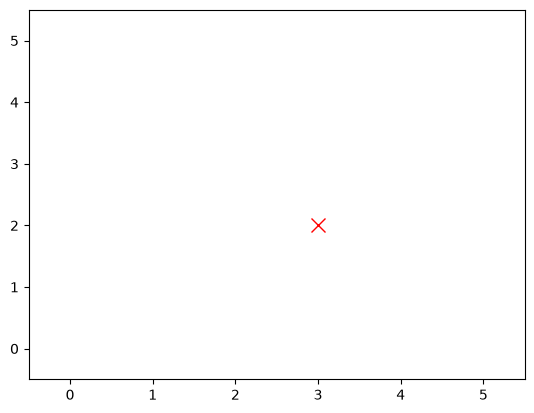

In [1]:
from matplotlib import pyplot as plt
import random 

x, y = [random.randrange(0,5)], [random.randrange(0,5)]
plt.xlim(-.5, 5.5)
plt.ylim(-.5, 5.5)
plt.plot(x, y, marker="x", markersize=10, color='red')
plt.show()

Now ask yourself this: what is the probability of shooting that specific spot you just fired on? Well... when you consider the entire wall and the infinite number of points to hit on it, you will realize it is incredibly unlikely. To further my point, let's draw a target around that hole we just created. 

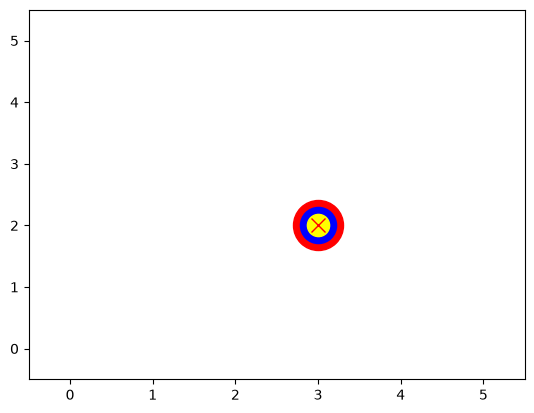

In [2]:
plt.xlim(-.5, 5.5)
plt.ylim(-.5, 5.5)
plt.plot(x, y, marker="o", markersize=36, color='red')
plt.plot(x, y, marker="o", markersize=26, color='blue')
plt.plot(x, y, marker="o", markersize=16, color='yellow')
plt.plot(x, y, marker="x", markersize=10, color='red')
plt.show()


Now I'm going to do something ridiculous. I'm going to bring my friends over and show my amazing marksmanship. "Look at the target I just hit!" I say. "It is so unlikely I would hit this EXACT spot and yet I did!" Think for a moment what the problem is here and move on. 

The problem is while hitting a specific target is extremely unlikely, it is easy to point out a target *after* it occurred. I can shoot blindly at a wall, draw a target around the hole, and point out the unlikely spot I just hit. *I never predicted the target, I observed it after it occurred.* This is what we call the **Texas Sharpshooter Fallacy** and it happens too often in scientific research. 

Consider another example: the probability of a specific player winning the lottery is extremely unlikely, but somebody *is* going to win the lottery. Let's simply simulate this below assuming there is only one winner in a million contestants. 

In [3]:
import random 

def play_lottery(number_of_contestants: int): 
    winner = random.randint(0,number_of_contestants)
    prob_of_win = 1 / number_of_contestants
    
    print(f"PLAYER {winner} WON THE LOTTERY!")
    print(f"They had a {round(prob_of_win * 100, 4)}% chance of winning.")
          

play_lottery(1_000_000)

PLAYER 17843 WON THE LOTTERY!
They had a 0.0001% chance of winning.


Are we surprised by the fact there is a winner?  No! It was completely random luck. If we predicted the winner, then that would be impressive and useful. But there's nothing remarkable about a specific person winning when nobody predicted that person would win. And yet, that person had an extremely unlikely chance of winning: 0.0001%. 

**The probability of an unlikely event is likely! We just do not know which one.**

This fallacy is also easy to do with data and analysis. The more data we have, the more targets we can stumble upon that were random coincidences. The targets can have a remarkably low p-value, and yet still be coincidental and passed on as significant. This is what we call p-hacking. 

## Data Mining and Simpson's Paradox 

Ask yourself this: is more data a good thing? 

Sure, having more data provides more opportunities to glean information. But when it comes to statistical findings it gets increasingly precarious. We can fall into a trap of finding more and more targets that happen to be hit, but did so by coincidence. We can make arguments that the p-values for these findings are low and significant. However, as said earlier the probability of unlikely events is likely, we just do not know which ones.  They are easy to identify in hindsight. 

Let's look at a dataset that studies possible variables that contribute to a dog's barking. 

In [4]:
import pandas as pd 

df = pd.read_csv("https://raw.githubusercontent.com/thomasnield/machine-learning-demo-data/797f82f66f2283bcb75d5ff8275c39f45167c2b6/regression/dog_barking.csv")
df

,AGE,SEX,ROOM_TEMPERATURE,NOISE_LEVEL,DOOR_KNOCKS,HOURS_OWNER_HOME,NUMBER_OF_BARKS
0,14,0,82.013274,17.664761,4,10.275816,8
1,9,0,75.149068,31.829007,2,12.143141,4
2,5,1,77.327897,30.222447,3,2.331137,3
3,9,1,78.940106,25.709314,3,9.276176,6
4,13,1,75.228578,23.518947,2,10.618847,4
5,1,1,68.887949,47.475772,3,9.941671,6
6,15,0,78.618823,26.096135,2,4.212029,4
7,15,1,79.577409,21.540774,1,8.235390,1
8,2,1,77.662010,36.371128,4,12.580167,8
9,3,1,72.305821,31.306230,3,2.508179,3


The right column is the number of barks, or the output variable we are interested in. The other variables include age, sex, room temperature, noise level, number of door knocks, and the number of hours the owner was home. Let's build a correlation matrix, which measures the strength of a correlation/relationship between each variable. A correlation value of 0 indicates no correlation, whereas a value closer to -1 or 1 indicates a strong negative or postive correlation respectively. 

In [5]:
df.corr(method='pearson')

,AGE,SEX,ROOM_TEMPERATURE,NOISE_LEVEL,DOOR_KNOCKS,HOURS_OWNER_HOME,NUMBER_OF_BARKS
AGE,1.000000,-0.043899,0.272279,-0.353125,0.024794,-0.220429,0.113427
SEX,-0.043899,1.000000,-0.186701,0.069225,0.126293,0.136415,0.062987
ROOM_TEMPERATURE,0.272279,-0.186701,1.000000,-0.016874,-0.088669,-0.025736,0.092899
NOISE_LEVEL,-0.353125,0.069225,-0.016874,1.000000,-0.274089,0.115979,-0.289047
DOOR_KNOCKS,0.024794,0.126293,-0.088669,-0.274089,1.000000,-0.015079,0.780277
HOURS_OWNER_HOME,-0.220429,0.136415,-0.025736,0.115979,-0.015079,1.000000,0.186578
NUMBER_OF_BARKS,0.113427,0.062987,0.092899,-0.289047,0.780277,0.186578,1.000000


There seems to be a decent positive correlation between `DOOR_KNOCKS` and `NUMBER_OF_BARKS`. This makes sense. Dogs tend to bark when the front door is knocked. But the other variables have very weak correlations. 

We could end our study here, and we should! But let's say the researcher is desperate to find something "interesting" or "groundbreaking." So the researcher now breaks up the data into different age ranges. 

He looks at dogs below between the ages of 4 through 7. Strangely, the correlation disappears between `DOOR_KNOCKS` and `NUMBER_OF_BARKS` with this group, and is now `-0.054233`. This is what we call **Simpson's Paradox**, where a pattern is reversed after a pattern is segmented.

In [6]:
filtered_df = df[(df["AGE"] <= 7) & (df["AGE"] >= 4)]
filtered_df.corr(method='pearson')

,AGE,SEX,ROOM_TEMPERATURE,NOISE_LEVEL,DOOR_KNOCKS,HOURS_OWNER_HOME,NUMBER_OF_BARKS
AGE,1.000000,0.447214,0.853166,0.445993,0.242536,-0.060762,0.559017
SEX,0.447214,1.000000,0.159882,-0.170384,0.759257,-0.141451,0.400000
ROOM_TEMPERATURE,0.853166,0.159882,1.000000,0.392381,0.087896,-0.293264,0.629597
NOISE_LEVEL,0.445993,-0.170384,0.392381,1.000000,0.263136,-0.458389,-0.365760
DOOR_KNOCKS,0.242536,0.759257,0.087896,0.263136,1.000000,-0.680775,-0.054233
HOURS_OWNER_HOME,-0.060762,-0.141451,-0.293264,-0.458389,-0.680775,1.000000,0.122564
NUMBER_OF_BARKS,0.559017,0.400000,0.629597,-0.365760,-0.054233,0.122564,1.000000


Next he looks at dogs between the ages of 8 and 11. Interestingly, it seems that dogs in the 8 to 11 years age group will bark less when noise level is higher, as the correlation between the two variables is `-0.700051`. 

In [7]:
filtered_df = df[(df["AGE"] <= 11) & (df["AGE"] >= 8)]
filtered_df.corr(method='pearson')

,AGE,SEX,ROOM_TEMPERATURE,NOISE_LEVEL,DOOR_KNOCKS,HOURS_OWNER_HOME,NUMBER_OF_BARKS
AGE,1.000000,-0.233854,-0.478999,-0.363709,-0.259608,-0.672373,-0.143419
SEX,-0.233854,1.000000,0.387623,-0.328991,0.237886,0.268045,0.452663
ROOM_TEMPERATURE,-0.478999,0.387623,1.000000,0.314305,-0.030612,0.144218,-0.049569
NOISE_LEVEL,-0.363709,-0.328991,0.314305,1.000000,-0.696240,0.142609,-0.700051
DOOR_KNOCKS,-0.259608,0.237886,-0.030612,-0.696240,1.000000,0.137641,0.823478
HOURS_OWNER_HOME,-0.672373,0.268045,0.144218,0.142609,0.137641,1.000000,-0.045103
NUMBER_OF_BARKS,-0.143419,0.452663,-0.049569,-0.700051,0.823478,-0.045103,1.000000


Now the researcher starts throwing around hypotheses. Maybe dogs in the 4 through 7 age range lose interest in barking at door knocks after doing it in their puppy years, but pick it up again when they are no longer burnt out! Maybe dogs in the 8 through 11 age range are more hard of hearing, and ambient noise levels drown out any other stimuli that will cause them to bark. 

See how we are driving ourselves crazy mining the data for findings, and we keep slicing and manipulating the data trying to find interesting conclusions? Does this practice sound familiar? 

![charlie](https://i.giphy.com/media/l0IylOPCNkiqOgMyA/giphy.webp "charlie")

*Courtesy: 20th Century Fox* 

Surprise!  This data is randomly generated, showing how easy it is to make spurious findings in even random data. This searching for patterns in data is known as data mining, and the correlations we stumbled on occurred completely by chance. For believability, I steered a positive correlation between door knocking and dog barking, but all other fields were completely random. This shows that correlations can be found in even randomly generated data, and therefore correlations can be meaningless. Random correlations can exist in the real world and is another reason why the mantra “correlation does not mean causation” is so important. 

If you want to see the exact code I used to make this dataset, here is the Pandas/NumPy declaration below. 

In [8]:
import numpy as np
import pandas as pd

pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)

n = 40
np.random.seed(7)
door_knocks =  np.random.normal(3, 1, n).astype(int)

df =  pd.DataFrame({"AGE" : np.random.randint(0,16,n),
                    "SEX" : np.random.randint(0,2, n),
                    "ROOM_TEMPERATURE" : np.random.normal(76, 4, n),
                    "NOISE_LEVEL": np.random.normal(30, 10, n),
                    "DOOR_KNOCKS" : door_knocks,
                    "HOURS_OWNER_HOME" : np.random.normal(7, 3, n),
                    "NUMBER_OF_BARKS" :  door_knocks * np.random.binomial(2,.85, n)
                   })

df

,AGE,SEX,ROOM_TEMPERATURE,NOISE_LEVEL,DOOR_KNOCKS,HOURS_OWNER_HOME,NUMBER_OF_BARKS
0,14,0,82.013274,17.664761,4,10.275816,8
1,9,0,75.149068,31.829007,2,12.143141,4
2,5,1,77.327897,30.222447,3,2.331137,3
3,9,1,78.940106,25.709314,3,9.276176,6
4,13,1,75.228578,23.518947,2,10.618847,4
5,1,1,68.887949,47.475772,3,9.941671,6
6,15,0,78.618823,26.096135,2,4.212029,4
7,15,1,79.577409,21.540774,1,8.235390,1
8,2,1,77.662010,36.371128,4,12.580167,8
9,3,1,72.305821,31.306230,3,2.508179,3


The problem with the previous examples is we practiced data mining rather than the scientific method.

**Data mining:** Gather data then hypothesize

**Scientific Method:** Hypothesize then gather data

The scientific method demands a structured hypothesis, and data is deliberately gathered to prove and disprove that hypothesis, by using a test group and a control group. Data mining is a free-for-all where we collect lots of data, and we hope to find hidden patterns and (untested) insights that may not be obvious, or even make sense! If data mining is used, it should ideally follow up with new data and testing, but many practitioners fail to do this. 

> **Is Machine Learning Data Mining?**

> Machine learning traverses a massive hypothesis space looking for hypotheses that correlate with the data, so it is in fact data mining. Think of machine learning as an automated data mining tool, evaluating numerous variable relationships in data. When we train an image classifier to recognize cows, it is data-mining to find pixels forming shapes that correlate with the label “cow. While this can be useful, it is not uncommon to find meaningless or wrong correlations between groups of pixels. For example, an image classifier may recognize empty fields as “cows,” because it was trained on fields with cows, but it correlated with the field rather than the cows.
The cows coincided with the field and thus resulted in a hypothesis that correlated on the wrong variables. 

## P-Hacking

P-hacking is cherry-picking models and data that produces a desired result rather than a realistic one. More specifically, P-hacking is data mining for a p-value of less than .05. Undisciplined and pressured practices are often the cause. Simply choosing a model because “it looks significant” or “solves my objective,” rather than challenging it, is a subtle and easy way to p-hack. 

This can lead to an inflation of false positives, where our model becomes too optimistic about an outcome but performs poorly in the wild. P-hacking is allegedly responsible for the replicability crisis1, and is arguably made worse with the availability of data and machine learning. 

**Examples of P-Hacking:**
* Collecting just enough data to get a desired result.
* Removing inconvenient data as “outliers” or “noise”
* Shopping for variables that give a desired result
* Dividing data into sub-groups, and focusing on one group
* Shopping model parameters that give the right result 
* Using random seeds that produce desired outcomes

**Motivations for P-Hacking** 
* Research pressure: “No paper, no funding”
* Job pressure: “Our client wants to see a model that predicts 10% savings in transportation costs”
* Startup pressure: “Our VC investors want a demonstration, so find a dataset that will produce favorable results.” 

Is P-hacking malicious and deceptive? Not usually, it is often human nature operating under pressure and career survival.

![](https://imgs.xkcd.com/comics/significant.png)

*Courtesy: XKCD.com *



## Data Bias 

As humans, we are strangely wired to be biased. We tend to look for patterns rather than reason why patterns might mislead us. Data bias is inevitable in statistics and data science work, so you should always be actively looking for it. If I survey college students at my local university and use my findings to represent all universities in the United States, there is obviously going to be bias. I'm favoring that university being represented over other universities, and making generalizations based on a limited sample. 

There are many types of bias, but one of the most pernicious types in statistics is *self-selection* bias. This occurs when certain types of subjects are more likely to include themselves in the experiment. If you go on a flight and survey the passengers what their favorite airline is, do not be surprised when it is the very airline they are flying! If you are doing phone surveys in the middle of a weekday, do not be surprised when most of your respondents are retirees, stay-at-home parents, and non-working individuals. These all can distort your findings because your intended population you are wanting to sample from is not including themselves in the sample. 

A variant of self-selection bias is **survivorship bias**, where only the "surviving" population is included in the sample and those that "perished" are never accounted for, as demonstrated in this XKCD cartoon. 

![](https://imgs.xkcd.com/comics/survivorship_bias.png)

Survivorship bias happens subtly. "Successful" companies and individuals often get written about and there are many books that analyze their qualities, but do not account that these qualities might also be common with failed companies and individuals too who failed in obscurity. 

In summary, be wary of bias and ask where the data came from and what might have steered it intentionally or unintentionally. Doing so will save you enormous headaches and projects that go awry. Bias does not go away with more data. It just creates more opportunities for bias to creep in. 

## Exercise

svg image

A vendor has approached your military aircraft operation. They have a statistical "AI" model that uses data collected from aircraft returning from combat and predicts where lightweight armor needs to be. It uses detailed data and statistical techniques identifying where bullet holes and damage are likely to be found. It then recommends armoring those hot spots.

What questions do you have for the vendor? Is their method sound? Why or why not? Are there any factors missing? Think carefully about this before moving on to the answer. 

### My response

The vendor's recommendation is not sound as stated because the training data include only aircraft that returned. This creates **survivorship bias**: damage in the observed hot spots is evidence that aircraft can survive hits there, while aircraft hit in critical areas may have been lost and therefore never entered the dataset. The missing outcomes are not random.

Before using the model, I would ask:

- Does the dataset include lost aircraft, recovered wreckage, maintenance records, mission exposure, aircraft type, and enemy weapon type?
- Are bullet-hole counts adjusted for the surface area and probability that each part was exposed to fire?
- How were damage locations measured, and are missing or ambiguous records documented?
- Was the armor recommendation tested prospectively on comparable missions, with aircraft loss and crew survival as outcomes?
- How does the model account for armor weight, balance, fuel use, maneuverability, and structural constraints?

The apparently undamaged areas on returning aircraft, such as engines, cockpit, fuel system, or other flight-critical structures, deserve priority investigation because hits there may prevent an aircraft from returning. Armor should be placed only after combining this inference with engineering knowledge, evidence about lost aircraft, and controlled validation. The model may help describe survivor damage, but it cannot by itself establish the causal locations where armor will reduce losses.

### SCROLL DOWN FOR ANSWER
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
|<br>
v 

svg image

This is a modernized version of a real statistics problem back in WWII. (https://apps.dtic.mil/docs/citations/ADA091073) 

The Center for Naval Analyses conducted a study on mitigating the loss of bombers. After analyzing fleets of bombers returned from missions, they conclude surfaces that statistically show the most damage should be prioritized for more armor. But a Hungarian mathematician named Abraham Wald pointed out a fatal flaw with this heuristic.

**The flaw: the data only captured survived aircraft, and therefore the approach was completely wrong.**

This is an example of survivership bias, where again we make faulty inferences on the survived population while the deceased population is never accounted for. While many would cynically say the data is incomplete, the data still provides a valuable clue to solve our objective. The question we should be asking: why did the aircraft return safely despite the observed damage? 

With success, Abraham flipped the theory by armoring the undamaged parts of the aircraft, inferring these were likely the critical areas causing a plane to go down and never returning to base. This not only saved aircraft and lives but was a pivotal moment for the war effort. 